# HMS Deep Learning Models (2024–2025)

Predict **`dep_or_anx`** (elevated depression and/or anxiety) on cleaned **2024–2025** Healthy Minds Study data using **5 PyTorch tabular models**.

| | |
|---|---|
| **Target** | `dep_or_anx` |
| **Inputs** | 25 features (demographics, wellbeing, substance use, discrimination, institution) |
| **Gender** | `gender_male`, `gender_female` only (`gender_nonbin` / `gender_trans` excluded) |
| **Models** | ResNet-MLP, TabNet, FT-Transformer, TabTransformer, DCNv2 |

In [1]:
# Installs into the *active Jupyter kernel* (not a different Python on your system)
%pip install -q pytorch-tabnet

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup & configuration

In [2]:
import random
import subprocess
import sys
import warnings
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn

try:
    from pytorch_tabnet.tab_model import TabNetClassifier
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pytorch-tabnet", "-q"])
    from pytorch_tabnet.tab_model import TabNetClassifier

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path(".").resolve()
OUTPUT_DIR = DATA_DIR / "exploration_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

TARGET = "dep_or_anx"
FEATURES = [
    "age", "gender_male", "gender_female",
    "international", "fincur", "finpast", "food_worry",
    "sleep_wknight", "sleep_wkend", "exerc",
    "belong1", "belong2", "lonely", "aca_impa", "flourish", "positiveMH",
    "sub_any", "binge1pl", "smok_cig",
    "discrim_race", "discrim_gender", "discrim_sexual",
    "inst_type", "inst_size", "inst_public",
]

BATCH_SIZE = 512
MAX_EPOCHS = 50
PATIENCE = 10
LR = 1e-3

print(f"Device: {DEVICE}")
print(f"Features: {len(FEATURES)}")

Device: cuda
Features: 25


In [3]:
def read_hms_csv(path: Path, **kwargs) -> pd.DataFrame:
    """Read an HMS CSV, handling mixed encodings in open-text responses."""
    opts = {"low_memory": False, **kwargs}
    for encoding in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):
        try:
            df = pd.read_csv(path, encoding=encoding, **opts)
            if encoding != "utf-8":
                print(f"[{encoding}]", end=" ")
            return df
        except UnicodeDecodeError:
            continue
    return pd.read_csv(path, encoding="utf-8", encoding_errors="replace", **opts)

## 2. Load & clean data

In [4]:
raw = read_hms_csv(DATA_DIR / "HMS_2024-2025_PUBLIC_instchars.csv")

cols = FEATURES + [TARGET, "nrweight", "Finished"]
df = raw[[c for c in cols if c in raw.columns]].copy()

for col in cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df[df["Finished"] == 1].copy()
df = df.dropna(subset=[TARGET])
df[TARGET] = df[TARGET].astype(int)

min_features = int(0.6 * len(FEATURES))
df = df[df[FEATURES].notna().sum(axis=1) >= min_features].copy()

print(f"Raw rows:      {len(raw):,}")
print(f"Cleaned rows:  {len(df):,}")
print(f"Positive rate: {df[TARGET].mean():.1%}")
df[FEATURES + [TARGET]].describe().T.head(10)

Raw rows:      84,735
Cleaned rows:  63,581
Positive rate: 44.9%


,count,mean,std,min,25%,50%,75%,max
age,63581.0,24.223982,8.286663,18.0,19.0,21.0,26.0,87.0
gender_male,17591.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
gender_female,42698.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0
international,63534.0,0.087134,0.282034,0.0,0.0,0.0,0.0,1.0
fincur,62509.0,2.756835,1.112906,1.0,2.0,3.0,3.0,5.0
finpast,62464.0,3.107214,1.262594,1.0,2.0,3.0,4.0,5.0
food_worry,62528.0,1.346021,0.594507,1.0,1.0,1.0,2.0,3.0
sleep_wknight,28573.0,6.583663,1.410165,1.0,6.0,7.0,7.0,9.0
sleep_wkend,28570.0,7.183374,1.098022,1.0,7.0,8.0,8.0,8.0
exerc,33111.0,2.947027,1.519918,1.0,2.0,3.0,4.0,5.0


## 3. Preprocessing — split, impute, scale, DataLoaders

In [5]:
X = df[FEATURES].values
y = df[TARGET].values.astype(np.float32)
w = df["nrweight"].values.astype(np.float32)

X_train, X_temp, y_train, y_temp, w_train, w_temp = train_test_split(
    X, y, w, test_size=0.2, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test, w_val, w_test = train_test_split(
    X_temp, y_temp, w_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

N_FEATURES = X_train.shape[1]
print(f"Train: {X_train.shape[0]:,} | Val: {X_val.shape[0]:,} | Test: {X_test.shape[0]:,}")


def make_loader(X_arr, y_arr, w_arr, shuffle=True):
    ds = TensorDataset(
        torch.tensor(X_arr, dtype=torch.float32),
        torch.tensor(y_arr, dtype=torch.float32),
        torch.tensor(w_arr, dtype=torch.float32),
    )
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)


train_loader = make_loader(X_train, y_train, w_train, shuffle=True)
val_loader = make_loader(X_val, y_val, w_val, shuffle=False)
test_loader = make_loader(X_test, y_test, w_test, shuffle=False)

Train: 50,864 | Val: 6,358 | Test: 6,359


## 4. Model architectures

In [6]:
class ResNetBlock(nn.Module):
    def __init__(self, d, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d, d),
            nn.BatchNorm1d(d),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d, d),
            nn.BatchNorm1d(d),
        )
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(x + self.net(x))


class ResNetMLP(nn.Module):
    def __init__(self, n_features, d=128, n_blocks=3, dropout=0.1):
        super().__init__()
        self.input = nn.Sequential(nn.Linear(n_features, d), nn.BatchNorm1d(d), nn.ReLU())
        self.blocks = nn.Sequential(*[ResNetBlock(d, dropout) for _ in range(n_blocks)])
        self.head = nn.Linear(d, 1)

    def forward(self, x):
        return self.head(self.blocks(self.input(x))).squeeze(-1)


class FTTransformer(nn.Module):
    """Feature Tokenizer + Transformer encoder (simplified FT-Transformer)."""

    def __init__(self, n_features, d_model=64, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        self.tokenizer = nn.ModuleList([nn.Linear(1, d_model) for _ in range(n_features)])
        self.cls = nn.Parameter(torch.randn(1, 1, d_model))
        enc_layer = nn.TransformerEncoderLayer(
            d_model, n_heads, dim_feedforward=d_model * 4,
            dropout=dropout, batch_first=True, activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Linear(d_model, 1))

    def forward(self, x):
        tokens = torch.stack([tok(x[:, i : i + 1]) for i, tok in enumerate(self.tokenizer)], dim=1)
        cls = self.cls.expand(x.size(0), -1, -1)
        h = self.encoder(torch.cat([cls, tokens], dim=1))
        return self.head(h[:, 0]).squeeze(-1)


class TabTransformer(nn.Module):
    """Column embeddings + self-attention over features."""

    def __init__(self, n_features, d_model=32, n_heads=4, n_layers=2, dropout=0.1):
        super().__init__()
        self.embed = nn.ModuleList([nn.Linear(1, d_model) for _ in range(n_features)])
        enc_layer = nn.TransformerEncoderLayer(
            d_model, n_heads, dim_feedforward=d_model * 4,
            dropout=dropout, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_features * d_model, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        h = torch.stack([e(x[:, i : i + 1]) for i, e in enumerate(self.embed)], dim=1)
        h = self.encoder(h)
        return self.head(h).squeeze(-1)


class CrossNetV2(nn.Module):
    def __init__(self, n_features, n_layers=2):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.Linear(n_features, n_features, bias=True) for _ in range(n_layers)
        ])

    def forward(self, x0):
        x = x0
        for w in self.layers:
            x = x0 * w(x) + x
        return x


class DCNv2(nn.Module):
    def __init__(self, n_features, cross_layers=2, hidden=128, dropout=0.1):
        super().__init__()
        self.cross = CrossNetV2(n_features, cross_layers)
        self.deep = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
        )
        self.head = nn.Linear(n_features + hidden, 1)

    def forward(self, x):
        cross_out = self.cross(x)
        deep_out = self.deep(x)
        return self.head(torch.cat([cross_out, deep_out], dim=1)).squeeze(-1)

## 5. Training utilities

In [7]:
def evaluate(model, loader, device=DEVICE):
    model.eval()
    preds, labels, weights = [], [], []
    total_loss, n = 0.0, 0
    criterion = nn.BCEWithLogitsLoss(reduction="none")
    with torch.no_grad():
        for xb, yb, wb in loader:
            xb, yb, wb = xb.to(device), yb.to(device), wb.to(device)
            logits = model(xb)
            loss = (criterion(logits, yb) * wb).sum() / wb.sum()
            total_loss += loss.item() * len(yb)
            n += len(yb)
            preds.append(torch.sigmoid(logits).cpu().numpy())
            labels.append(yb.cpu().numpy())
            weights.append(wb.cpu().numpy())
    preds = np.concatenate(preds)
    labels = np.concatenate(labels)
    weights = np.concatenate(weights)
    pred_bin = (preds >= 0.5).astype(int)
    try:
        auc = roc_auc_score(labels, preds, sample_weight=weights)
    except ValueError:
        auc = float("nan")
    return {
        "loss": total_loss / n,
        "auc": auc,
        "accuracy": accuracy_score(labels, pred_bin, sample_weight=weights),
        "f1": f1_score(labels, pred_bin, sample_weight=weights, zero_division=0),
        "proba": preds,
        "y_true": labels,
    }


def train_pytorch_model(model, name, train_loader, val_loader, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss(reduction="none")
    best_auc, best_state, wait = -1.0, None, 0
    history = {"train_loss": [], "val_loss": [], "val_auc": []}

    for epoch in range(1, max_epochs + 1):
        model.train()
        train_loss, n = 0.0, 0
        for xb, yb, wb in train_loader:
            xb, yb, wb = xb.to(DEVICE), yb.to(DEVICE), wb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = (criterion(logits, yb) * wb).sum() / wb.sum()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(yb)
            n += len(yb)

        val_metrics = evaluate(model, val_loader)
        history["train_loss"].append(train_loss / n)
        history["val_loss"].append(val_metrics["loss"])
        history["val_auc"].append(val_metrics["auc"])

        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"  {name}: early stop at epoch {epoch} (best val AUC={best_auc:.4f})")
                break
    else:
        print(f"  {name}: finished {max_epochs} epochs (best val AUC={best_auc:.4f})")

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, history

## 6. Train all 5 deep learning models

In [8]:
results = {}
histories = {}

pytorch_models = {
    "ResNet-MLP": ResNetMLP(N_FEATURES),
    "FT-Transformer": FTTransformer(N_FEATURES),
    "TabTransformer": TabTransformer(N_FEATURES),
    "DCNv2": DCNv2(N_FEATURES),
}

trained_models = {}
for name, model in pytorch_models.items():
    print(f"Training {name}...")
    trained, hist = train_pytorch_model(model, name, train_loader, val_loader)
    trained_models[name] = trained
    histories[name] = hist
    test_m = evaluate(trained, test_loader)
    results[name] = {k: test_m[k] for k in ["auc", "accuracy", "f1"]}
    results[name]["proba"] = test_m["proba"]
    print(f"  Test AUC={test_m['auc']:.4f} | Acc={test_m['accuracy']:.4f} | F1={test_m['f1']:.4f}")

Training ResNet-MLP...
  ResNet-MLP: early stop at epoch 13 (best val AUC=0.8610)
  Test AUC=0.8587 | Acc=0.7793 | F1=0.7646
Training FT-Transformer...
  FT-Transformer: early stop at epoch 13 (best val AUC=0.8690)
  Test AUC=0.8640 | Acc=0.7872 | F1=0.7780
Training TabTransformer...
  TabTransformer: early stop at epoch 14 (best val AUC=0.8702)
  Test AUC=0.8636 | Acc=0.7876 | F1=0.7691
Training DCNv2...
  DCNv2: early stop at epoch 13 (best val AUC=0.8659)
  Test AUC=0.8627 | Acc=0.7816 | F1=0.7670


In [9]:
# TabNet (separate API — uses numpy arrays + sample weights)
print("Training TabNet...")
tabnet = TabNetClassifier(
    n_d=32, n_a=32, n_steps=3,
    gamma=1.3, lambda_sparse=1e-4,
    optimizer_fn=torch.optim.AdamW,
    optimizer_params=dict(lr=LR, weight_decay=1e-4),
    scheduler_params={"step_size": 10, "gamma": 0.9},
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    seed=SEED,
    verbose=0,
)
tabnet.fit(
    X_train, y_train.astype(int),
    eval_set=[(X_val, y_val.astype(int))],
    eval_metric=["auc"],
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
    batch_size=BATCH_SIZE,
    weights=w_train,
    drop_last=False,
)
tabnet_proba = tabnet.predict_proba(X_test)[:, 1]
tabnet_pred = (tabnet_proba >= 0.5).astype(int)
results["TabNet"] = {
    "auc": roc_auc_score(y_test, tabnet_proba, sample_weight=w_test),
    "accuracy": accuracy_score(y_test, tabnet_pred, sample_weight=w_test),
    "f1": f1_score(y_test, tabnet_pred, sample_weight=w_test, zero_division=0),
    "proba": tabnet_proba,
}
print(f"  Test AUC={results['TabNet']['auc']:.4f} | Acc={results['TabNet']['accuracy']:.4f} | F1={results['TabNet']['f1']:.4f}")

Training TabNet...

Early stopping occurred at epoch 37 with best_epoch = 27 and best_val_0_auc = 0.85319
  Test AUC=0.8520 | Acc=0.7812 | F1=0.7615


## 7. Sklearn baseline (same splits)

In [10]:
lr_baseline = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_baseline.fit(X_train, y_train, sample_weight=w_train)
lr_proba = lr_baseline.predict_proba(X_test)[:, 1]
lr_pred = lr_baseline.predict(X_test)
results["Logistic Regression (baseline)"] = {
    "auc": roc_auc_score(y_test, lr_proba, sample_weight=w_test),
    "accuracy": accuracy_score(y_test, lr_pred, sample_weight=w_test),
    "f1": f1_score(y_test, lr_pred, sample_weight=w_test, zero_division=0),
    "proba": lr_proba,
}
print(f"Baseline Test AUC={results['Logistic Regression (baseline)']['auc']:.4f}")

Baseline Test AUC=0.8573


## 8. Comparison & export

In [11]:
comparison = pd.DataFrame(
    {name: {k: v for k, v in m.items() if k != "proba"} for name, m in results.items()}
).T.round(4)
comparison = comparison.sort_values("auc", ascending=False)
comparison

,auc,accuracy,f1
FT-Transformer,0.8640,0.7872,0.7780
TabTransformer,0.8636,0.7876,0.7691
DCNv2,0.8627,0.7816,0.7670
ResNet-MLP,0.8587,0.7793,0.7646
Logistic Regression (baseline),0.8573,0.7830,0.7722
TabNet,0.8520,0.7812,0.7615


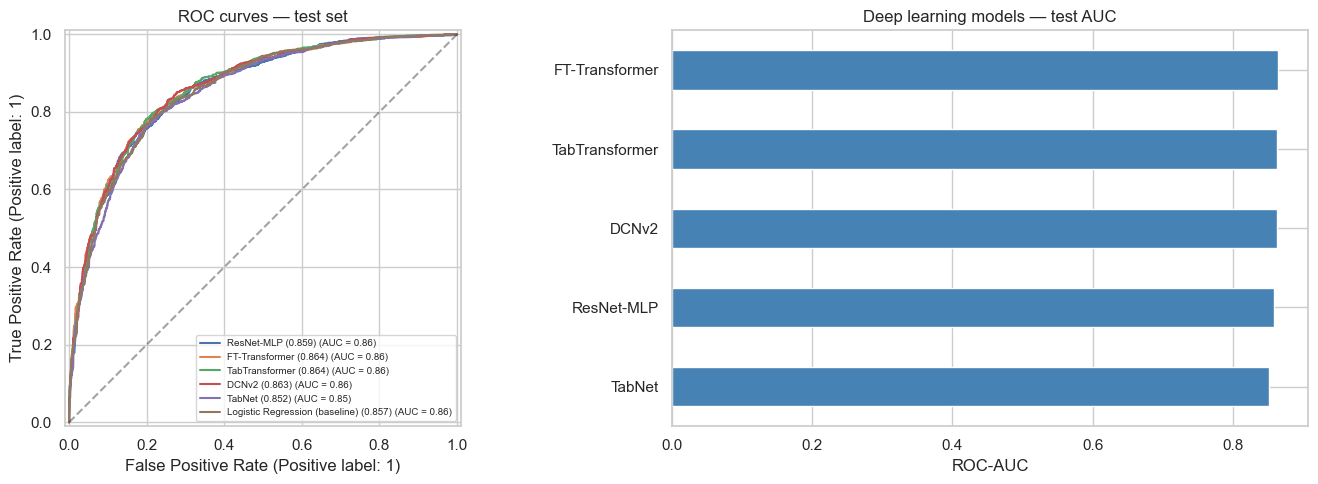

Saved: C:\Users\test\Desktop\2007-2025 datasets (.csv, .dta)\exploration_outputs\dl_model_comparison.csv


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, m in results.items():
    if "proba" in m:
        RocCurveDisplay.from_predictions(
            y_test, m["proba"], sample_weight=w_test,
            name=f"{name} ({m['auc']:.3f})", ax=axes[0],
        )
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("ROC curves — test set")
axes[0].legend(fontsize=7, loc="lower right")

dl_only = comparison.drop(index="Logistic Regression (baseline)", errors="ignore")
dl_only["auc"].sort_values().plot(kind="barh", ax=axes[1], color="steelblue", edgecolor="white")
axes[1].set_xlabel("ROC-AUC")
axes[1].set_title("Deep learning models — test AUC")

plt.tight_layout()
plt.show()

comparison.to_csv(OUTPUT_DIR / "dl_model_comparison.csv")
print(f"Saved: {OUTPUT_DIR / 'dl_model_comparison.csv'}")

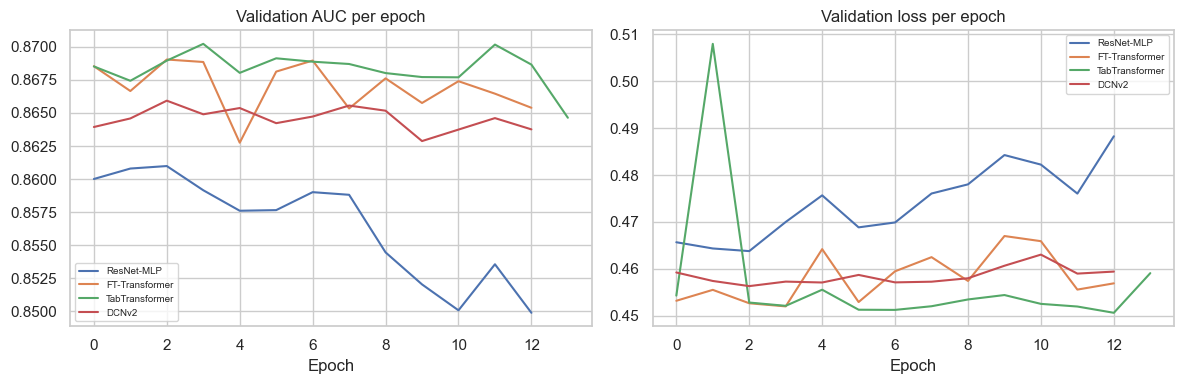

In [13]:
# Validation learning curves for PyTorch models
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, hist in histories.items():
        axes[0].plot(hist["val_auc"], label=name)
        axes[1].plot(hist["val_loss"], label=name)
    axes[0].set_title("Validation AUC per epoch")
    axes[0].set_xlabel("Epoch")
    axes[0].legend(fontsize=7)
    axes[1].set_title("Validation loss per epoch")
    axes[1].set_xlabel("Epoch")
    axes[1].legend(fontsize=7)
    plt.tight_layout()
    plt.show()

## Notes

- **Target:** `dep_or_anx` — not for clinical deployment; research/exploration only.
- **No leakage:** PHQ-9/GAD-7 symptom scores excluded from inputs.
- **Gender:** only `gender_male` and `gender_female` retained.
- **Weights:** `nrweight` used in loss (PyTorch) and TabNet fit.
- **Imbalance:** ~45% positive class; early stopping on validation AUC.